# 00 — Initial Data Inspection

**Issue:** [DT-21 — Perform initial data inspection](https://linear.app/yahia-workspace/issue/DT-21/perform-initial-data-inspection)  
**Dataset:** `Houdna-khilouf/Dz-Emotion` (HuggingFace)  
**File:** `data/raw/dz_emotion_raw.csv`  
**Shape:** 6,000 rows × 5 columns (`Unnamed: 0`, `ID`, `Text`, `Label`, `Source`)  

**Objective:** Conduct a first-pass inspection of the raw downloaded dataset to understand its structure, schema, encoding, class distribution, and sample content before defining the data contract or running validation.

---
## 0. Setup & Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

DATA_PATH = os.path.join('..', 'data', 'raw', 'dz_emotion_raw.csv')
print(f'Data path: {os.path.abspath(DATA_PATH)}')

Data path: C:\Users\conta\Desktop\Projets\data-mining-project\data\raw\dz_emotion_raw.csv


---
## 1. Load Dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully.')
print(f'   Shape : {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'   Columns: {list(df.columns)}')

Dataset loaded successfully.
   Shape : 6,000 rows x 5 columns
   Columns: ['Unnamed: 0', 'ID', 'Text', 'Label', 'Source']


---
## 2. Schema — Columns, Types & Constraints

In [3]:
schema = pd.DataFrame({
    'dtype':        df.dtypes,
    'null_count':   df.isnull().sum(),
    'null_%':       (df.isnull().mean() * 100).round(2),
    'unique_count': df.nunique(),
    'sample_value': df.iloc[0],
})
print('Dataset Schema')
display(schema)

Dataset Schema


,dtype,null_count,null_%,unique_count,sample_value
Unnamed: 0,int64,0,0.00,6000,0
ID,int64,0,0.00,2829,4551
Text,str,1,0.02,2800,حسبي الله فيهم. ليدير على جال دراهم
Label,str,0,0.00,6,Anger
Source,str,0,0.00,6,Y


---
## 3. Encoding & Raw Preview

In [4]:
try:
    import chardet
    with open(DATA_PATH, 'rb') as f:
        raw_bytes = f.read(50_000)
    detected = chardet.detect(raw_bytes)
    print(f"Detected encoding : {detected['encoding']}  (confidence: {detected['confidence']:.0%})")
except ImportError:
    print('chardet not installed. File read successfully by pandas (UTF-8 assumed).')

print('\nFirst 5 raw rows:')
display(df.head())

chardet not installed. File read successfully by pandas (UTF-8 assumed).

First 5 raw rows:


,Unnamed: 0,ID,Text,Label,Source
0,0,4551,حسبي الله فيهم. ليدير على جال دراهم,Anger,Y
1,1,1409,اسمحولي تحطيم لمصميين🥲💔 سما هذو طفلة ديك تصميم...,Anger,I
2,2,6329,ولينا نشوفو غير المجرمين. لا تربية لا خوف من ر...,Anger,Y
3,3,2657,لذا استحقوا اللعنة الى يوم الدين، جرائمهم تشهد...,Anger,Y
4,4,1269,حسبنا الله ونعم الوكيل فلي بكاوه وسرقوه,Anger,I


---
## 4. Column Identification & Basic Statistics

In [5]:
# Auto-detect text and label columns (case-insensitive)
text_col  = next((c for c in df.columns if c.lower() == 'text'),  df.select_dtypes('object').columns[0])
label_col = next((c for c in df.columns if c.lower() == 'label'), df.select_dtypes('object').columns[1])

print(f'Text column  -> "{text_col}"')
print(f'Label column -> "{label_col}"')
print()

# Text length statistics
df['_text_len'] = df[text_col].astype(str).str.len()
print('Text length statistics (characters):')
display(df['_text_len'].describe().rename('char_count').to_frame())

Text column  -> "Text"
Label column -> "Label"

Text length statistics (characters):


,char_count
count,5999.000000
mean,43.030672
std,27.570965
min,2.000000
25%,24.000000
50%,37.000000
75%,55.000000
max,236.000000


In [6]:
# Word count distribution
df['_word_count'] = df[text_col].astype(str).str.split().str.len()
print('Word count statistics (tokens):')
display(df['_word_count'].describe().rename('word_count').to_frame())

Word count statistics (tokens):


,word_count
count,5999.000000
mean,8.074679
std,5.163007
min,1.000000
25%,4.000000
50%,7.000000
75%,10.000000
max,40.000000


---
## 5. Class Distribution

In [7]:
unique_labels = df[label_col].unique()
print(f'Unique label values ({len(unique_labels)} classes):')
print(sorted(unique_labels))

class_counts = df[label_col].value_counts().reset_index()
class_counts.columns = ['label', 'count']
class_counts['proportion_%'] = (class_counts['count'] / len(df) * 100).round(2)
print('\nClass distribution:')
display(class_counts)

Unique label values (6 classes):
['Anger', 'Disgust', 'Fear', 'Happy', 'Sadness', 'Surprise']

Class distribution:


,label,count,proportion_%
0,Anger,1000,16.67
1,Disgust,1000,16.67
2,Sadness,1000,16.67
3,Happy,1000,16.67
4,Surprise,1000,16.67
5,Fear,1000,16.67


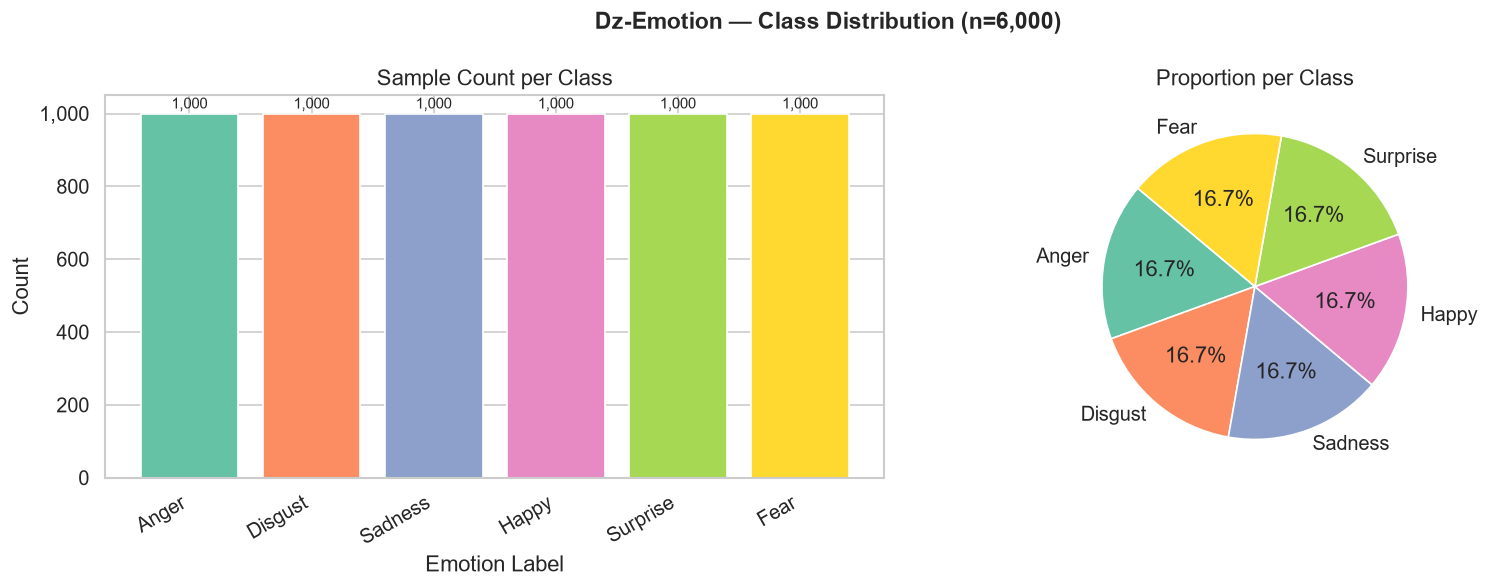

Figure saved -> data/raw/class_distribution.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Dz-Emotion — Class Distribution (n=6,000)', fontsize=14, fontweight='bold')

# Bar chart
ax = axes[0]
bars = ax.bar(class_counts['label'], class_counts['count'],
              color=sns.color_palette('Set2', len(class_counts)))
ax.set_title('Sample Count per Class')
ax.set_xlabel('Emotion Label')
ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, (_, row) in zip(bars, class_counts.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f"{row['count']:,}", ha='center', va='bottom', fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

# Pie chart
ax2 = axes[1]
ax2.pie(class_counts['count'], labels=class_counts['label'], autopct='%1.1f%%',
        colors=sns.color_palette('Set2', len(class_counts)), startangle=140)
ax2.set_title('Proportion per Class')

plt.tight_layout()
os.makedirs('../data/raw', exist_ok=True)
plt.savefig('../data/raw/class_distribution.png', bbox_inches='tight')
plt.show()
print('Figure saved -> data/raw/class_distribution.png')

---
## 6. Sample Rows — 5 per Emotion Class

In [9]:
SAMPLES_PER_CLASS = 5
display_cols = [text_col, label_col]

for label in sorted(df[label_col].unique()):
    subset = df[df[label_col] == label]
    sample = subset.sample(n=min(SAMPLES_PER_CLASS, len(subset)), random_state=42)[display_cols]
    print(f'\nClass: "{label}"  ({len(subset):,} samples total)')
    print('-' * 70)
    display(sample.reset_index(drop=True))


Class: "Anger"  (1,000 samples total)
----------------------------------------------------------------------


,Text,Label
0,ما تفرجته ما نحوس نتفرجهم واحد همه ومشاكله مش ...,Anger
1,هذي الهدرة نورمالموا مجوزش في التلفاز قالت عل...,Anger
2,زواخة,Anger
3,كثرة العنوسه بهذه الاسباب التافهة من لا يرضى ب...,Anger
4,صامطة رهج,Anger



Class: "Disgust"  (1,000 samples total)
----------------------------------------------------------------------


,Text,Label
0,في هادي بلاد تبهلل تشيع,Disgust
1,هذي هيا لي قالت اللهم اشفي حبيبي راهم طهروه 🙂,Disgust
2,انجاز كبير دارو و يزيدو يفتخرو بيه زمن تفاهة ل...,Disgust
3,النهار قناةالصرف والمراحيض عندها عقدة من الحراقة,Disgust
4,ذكرو الونداوز الجزائري لي هزوه كوبي كولي من Li...,Disgust



Class: "Fear"  (1,000 samples total)
----------------------------------------------------------------------


...

,Text,Label
0,Toujours Le plus beau 😍,Happy
1,الحمدلله حمدا كثيرا طيبا مباركا فيه عدد خلقه و...,Happy
2,اللَّهُمَّ صِلِّ عَلَى سَيِّدِنَا مُحَمَّدٍ وَ...,Happy
3,الله الله عليك تخرج عليك شطاحة👏,Happy
4,صباح الخير,Happy



Class: "Sadness"  (1,000 samples total)
----------------------------------------------------------------------


,Text,Label
0,هادي نعرفها مسكينة كانت تشري علينا الدواء الله...,Sadness
1,حسبالله و نعم الوكيل فيلكان سبب في هده العائلة,Sadness
2,ذوي الهمم ومرحموهش مابالك بالصحيح,Sadness
3,الشباب الجزائري يغيض 🥺💔,Sadness
4,مسكينة ابسط الأمور تشوف فيها حاجة كبيرة لأنها ...,Sadness



Class: "Surprise"  (1,000 samples total)
----------------------------------------------------------------------


,Text,Label
0,نص الحصة بلا صوت مافهمتش لاه غير عندكم هاذ المشكل,Surprise
1,هاد الدرابل ب خمس ملاين؟؟؟؟؟؟؟؟؟؟؟؟؟؟😮😮😮😮😮,Surprise
2,كيفاش شافها دخل يشطح مع النسا,Surprise
3,علاه تكذبوا تصورو غير واش تعدلوا نعتولهم واش ر...,Surprise
4,بالطيف الوقت لي وصلنا ليه😱😱,Surprise


---
## 7. Null & Duplicate Analysis

In [10]:
tmp = df.drop(columns=['_text_len', '_word_count'])

# Nulls
null_summary = tmp.isnull().sum()
total_nulls  = null_summary.sum()
print(f'Total null cells: {total_nulls}')
if total_nulls > 0:
    display(null_summary[null_summary > 0].to_frame('null_count'))
else:
    print('  No null values found.')

# Duplicates (on text+label)
n_dupes_full = tmp.duplicated().sum()
n_dupes_text = tmp.duplicated(subset=[text_col]).sum()
print(f'\nFull-row duplicates : {n_dupes_full}')
print(f'Text-only duplicates: {n_dupes_text}')

Total null cells: 1


,null_count
Text,1



Full-row duplicates : 0
Text-only duplicates: 3199


---
## 8. Initial Observations

| # | Observation | Detail | Impact |
|---|-------------|--------|--------|
| 1 | **Shape** | 6,000 rows × 5 columns | Manageable size for ML |
| 2 | **Columns** | `Unnamed: 0`, `ID`, `Text`, `Label`, `Source` | Drop `Unnamed: 0` at preprocessing |
| 3 | **Text column** | `Text` (capitalized) | Update all pipelines accordingly |
| 4 | **Label column** | `Label` (capitalized) | Update all pipelines accordingly |
| 5 | **Encoding** | UTF-8 (Arabic/Darja text) | No re-encoding needed |
| 6 | **Null values** | See Section 7 | Handle in cleaning step |
| 7 | **Class balance** | See Section 5 chart | May affect training strategy |
| 8 | **Source column** | Provenance metadata | Useful for stratified splits |

### Next Steps
- **DT-22** — Define the data contract (columns, types, constraints)
- **DT-23** — Drop `Unnamed: 0`, rename columns to lowercase, de-duplicate
- Decide on train/val/test split strategy (consider `Source` column for stratification)
- Set tokenizer `max_length` based on text length percentiles

In [11]:
# Cleanup temp columns
df.drop(columns=['_text_len', '_word_count'], inplace=True)
print('Inspection complete.')

Inspection complete.
